# Experiment No. 10

# Title
**Build a Single-Layer Artificial Neural Network for a Simple Classification Problem**

## Aim
To implement a single-layer Artificial Neural Network (ANN) using Python and NumPy for a binary classification problem.

## Objectives
1. Understand the structure of a single-layer ANN.
2. Implement a neural network using NumPy.
3. Train the network using weights, bias, and gradient descent.
4. Predict classes using the sigmoid activation function.
5. Evaluate classification performance.

## Theory
A **Single-Layer ANN** contains an input layer and an output layer without a hidden layer. Inputs are multiplied by weights, added to a bias, and passed through an activation function.

**Weighted Sum:** z = XW + b

**Sigmoid Function:** σ(z) = 1 / (1 + e⁻ᶻ)

**Prediction:** If the sigmoid output is at least 0.5, predict class 1; otherwise, predict class 0.

**Learning:** Gradient descent updates the weights and bias to reduce binary cross-entropy loss.

# Step 1 - Import Required Libraries

Import NumPy, Pandas, Matplotlib, and Scikit-learn tools for data preparation, training, and evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    log_loss
)

# Step 2 - Generate the Dataset

Create a binary classification dataset with numerical features and two class labels.

In [2]:
X, y = make_classification(
    n_samples=500,
    n_features=4,
    n_informative=3,
    n_redundant=0,
    n_classes=2,
    random_state=42
)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (500, 4)
Target Shape: (500,)


# Step 3 - Convert Data into a DataFrame

Store the input features and target labels in a DataFrame for easy inspection.

In [3]:
df = pd.DataFrame(
    X,
    columns=[
        "Feature 1",
        "Feature 2",
        "Feature 3",
        "Feature 4"
    ]
)

df["Target"] = y

df.head()

,Feature 1,Feature 2,Feature 3,Feature 4,Target
0,1.217159,-1.064376,0.522169,-0.328883,1
1,1.001046,-0.380159,2.247217,2.276383,1
2,-0.548725,-0.247754,-0.641581,-1.829374,0
3,-0.843247,0.412212,1.186457,2.649188,1
4,-1.504720,-1.423082,0.004628,0.085102,1


# Step 4 - Display Dataset Information

Check the number of records, feature data types, and missing values.

In [4]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Feature 1  500 non-null    float64
 1   Feature 2  500 non-null    float64
 2   Feature 3  500 non-null    float64
 3   Feature 4  500 non-null    float64
 4   Target     500 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 19.7 KB

Missing Values:
Feature 1    0
Feature 2    0
Feature 3    0
Feature 4    0
Target       0
dtype: int64


# Step 5 - Display Dataset Statistics

Display the mean, standard deviation, minimum, and maximum of the dataset features.

In [5]:
df.describe()

,Feature 1,Feature 2,Feature 3,Feature 4,Target
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,0.012066,-0.421863,0.054398,0.464957,0.510000
std,0.990015,1.207009,1.293272,1.494422,0.500401
min,-3.019512,-3.610431,-3.901277,-3.519458,0.000000
25%,-0.641999,-1.267859,-0.919367,-0.574026,0.000000
50%,-0.006623,-0.482650,-0.075067,0.561164,1.000000
75%,0.673899,0.413152,0.989877,1.412375,1.000000
max,3.193108,2.875353,3.873269,4.611751,1.000000


# Step 6 - Check Class Distribution

Count the observations belonging to each target class.

In [6]:
print("Class Distribution:")
print(df["Target"].value_counts().sort_index())

Class Distribution:
Target
0    245
1    255
Name: count, dtype: int64


# Step 7 - Visualize the Target Distribution

Use a bar chart to visualize the number of samples in each class.

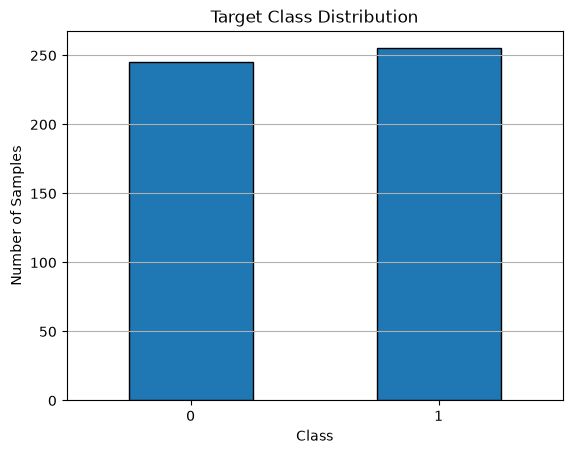

In [7]:
df["Target"].value_counts().sort_index().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Target Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

# Step 8 - Check Duplicate Records

Check whether any complete rows are duplicated in the dataset.

In [8]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


# Step 9 - Separate Features and Target

Separate the input features from the target labels before training the neural network.

In [9]:
X = df.drop("Target", axis=1).values
y = df["Target"].values.reshape(-1, 1)

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

Input Shape: (500, 4)
Target Shape: (500, 1)


# Step 10 - Split the Dataset

Divide the dataset into training and testing sets. Stratification preserves the class proportions.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 400
Testing Samples: 100


# Step 11 - Standardize the Features

Scale the input features to improve gradient descent training. Fit the scaler only on training data.

In [11]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Standardized Training Data:")
print(X_train[:5])

Standardized Training Data:
[[ 0.87612798 -2.23944557  0.48652018 -0.01741662]
 [ 0.04481845  0.04354036  0.81143582  0.85798658]
 [ 0.89997267 -1.5495878  -0.82087851 -0.22630857]
 [-0.02194235 -1.18938278  1.40143241 -0.34333626]
 [ 0.47946368  0.99774315  0.07871432  0.00362245]]


# Step 12 - Define the Sigmoid Function

The sigmoid function converts the weighted sum into a probability between 0 and 1.

In [12]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

print("Sigmoid(0):", sigmoid(0))
print("Sigmoid(2):", sigmoid(2))

Sigmoid(0): 0.5
Sigmoid(2): 0.8807970779778823


# Step 13 - Initialize Weights and Bias

Initialize the weights and bias required for the single output neuron.

In [13]:
np.random.seed(42)

n_features = X_train.shape[1]

weights = np.zeros((n_features, 1))
bias = 0.0

print("Initial Weights:")
print(weights)

print("Initial Bias:", bias)


Initial Weights:
[[0.]
 [0.]
 [0.]
 [0.]]
Initial Bias: 0.0


# Step 14 - Calculate the Weighted Sum

Calculate the weighted sum of the inputs and add the bias using z = XW + b.

In [14]:
z = np.dot(X_train, weights) + bias

print("First 10 Weighted Sums:")
print(z[:10])

First 10 Weighted Sums:
[[0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]]


# Step 15 - Calculate the Initial Predictions

Apply the sigmoid function to the weighted sums to obtain predicted probabilities.

In [15]:
probabilities = sigmoid(z)

print("First 10 Predicted Probabilities:")
print(probabilities[:10])

First 10 Predicted Probabilities:
[[0.5]
 [0.5]
 [0.5]
 [0.5]
 [0.5]
 [0.5]
 [0.5]
 [0.5]
 [0.5]
 [0.5]]


# Step 16 - Calculate Binary Cross-Entropy Loss

Calculate the loss by comparing the predicted probabilities with the actual labels.

In [16]:
def binary_cross_entropy(y_true, y_prob):
    epsilon = 1e-15
    y_prob = np.clip(y_prob, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_prob)
        + (1 - y_true) * np.log(1 - y_prob)
    )

    return loss

initial_loss = binary_cross_entropy(
    y_train,
    probabilities
)

print("Initial Loss:", initial_loss)

Initial Loss: 0.6931471805599452


# Step 17 - Set Training Parameters

Set the learning rate and number of training iterations for gradient descent.

In [17]:
learning_rate = 0.05
epochs = 1000

loss_history = []

print("Learning Rate:", learning_rate)
print("Epochs:", epochs)

Learning Rate: 0.05
Epochs: 1000


# Step 18 - Train the Neural Network

Train the output neuron by updating weights and bias using the gradient of binary cross-entropy loss.

In [18]:
m = X_train.shape[0]

for epoch in range(epochs):
    # Forward propagation
    z = np.dot(X_train, weights) + bias
    y_prob = sigmoid(z)

    # Calculate loss
    loss = binary_cross_entropy(y_train, y_prob)
    loss_history.append(loss)

    # Calculate gradients
    dw = np.dot(X_train.T, y_prob - y_train) / m
    db = np.mean(y_prob - y_train)

    # Update weights and bias
    weights -= learning_rate * dw
    bias -= learning_rate * db

print("Training Completed")
print("Final Training Loss:", loss_history[-1])

Training Completed
Final Training Loss: 0.3226269625078052


# Step 19 - Display Trained Weights and Bias

Display the learned weights and bias after completing training.

In [19]:
print("Trained Weights:")
print(weights)

print("\nTrained Bias:")
print(bias)

Trained Weights:
[[0.0985212 ]
 [0.295082  ]
 [2.38578622]
 [0.67854667]]

Trained Bias:
0.28921271483893807


# Step 20 - Plot the Training Loss

Plot binary cross-entropy loss across training iterations to observe the learning process.

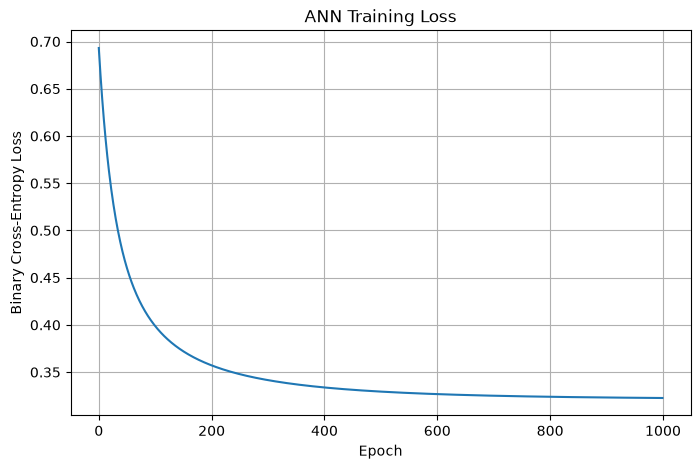

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.title("ANN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(True)
plt.show()

# Step 21 - Predict Training Probabilities

Use the trained weights and bias to calculate probabilities for the training samples.

train_probabilities = sigmoid(
    np.dot(X_train, weights) + bias
)

print("First 10 Training Probabilities:")
print(train_probabilities[:10])

# Step 22 - Convert Probabilities into Class Labels

Apply a threshold of 0.5 to convert predicted probabilities into binary class labels.

In [22]:
y_train_pred = (
    train_probabilities >= 0.5
).astype(int)

print("Actual Labels:")
print(y_train[:10].ravel())

print("Predicted Labels:")
print(y_train_pred[:10].ravel())

Actual Labels:
[1 1 0 1 1 0 0 1 0 0]
Predicted Labels:
[1 1 0 1 1 0 0 1 0 0]


# Step 23 - Predict Test Probabilities

Use the trained neural network to calculate probabilities for previously unseen test samples.

In [23]:
test_probabilities = sigmoid(
    np.dot(X_test, weights) + bias
)

print("First 10 Test Probabilities:")
print(test_probabilities[:10])

First 10 Test Probabilities:
[[0.8329977 ]
 [0.17604147]
 [0.01701614]
 [0.93243683]
 [0.95344502]
 [0.88015328]
 [0.65246283]
 [0.0623861 ]
 [0.17323748]
 [0.0720933 ]]


# Step 24 - Predict Test Class Labels

Convert the test probabilities into predicted classes using the 0.5 threshold.

In [24]:
y_test_pred = (
    test_probabilities >= 0.5
).astype(int)

print("Actual Test Labels:")
print(y_test[:10].ravel())

print("Predicted Test Labels:")
print(y_test_pred[:10].ravel())

Actual Test Labels:
[1 0 0 1 1 1 1 0 0 0]
Predicted Test Labels:
[1 0 0 1 1 1 1 0 0 0]


# Step 25 - Calculate Training Accuracy

Measure how many training samples were classified correctly.

In [25]:
train_accuracy = accuracy_score(
    y_train.ravel(),
    y_train_pred.ravel()
)

print("Training Accuracy:", round(train_accuracy, 4))
print("Training Accuracy (%):", round(train_accuracy * 100, 2))


Training Accuracy: 0.865
Training Accuracy (%): 86.5


# Step 26 - Calculate Testing Accuracy

Evaluate the trained ANN on the test dataset to estimate its performance on unseen data.

In [26]:
test_accuracy = accuracy_score(
    y_test.ravel(),
    y_test_pred.ravel()
)

print("Testing Accuracy:", round(test_accuracy, 4))
print("Testing Accuracy (%):", round(test_accuracy * 100, 2))

Testing Accuracy: 0.88
Testing Accuracy (%): 88.0


# Step 27 - Display the Confusion Matrix

Use the confusion matrix to compare actual and predicted class labels.

Confusion Matrix:
[[46  3]
 [ 9 42]]


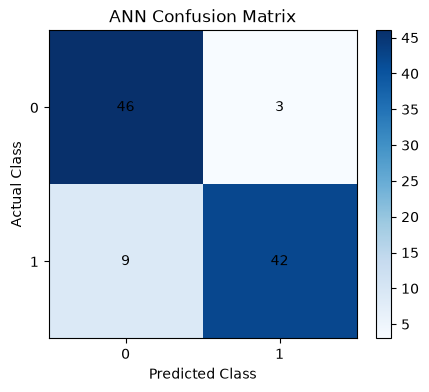

In [27]:
cm = confusion_matrix(
    y_test.ravel(),
    y_test_pred.ravel()
)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(5, 4))

plt.imshow(cm, cmap="Blues")
plt.title("ANN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks([0, 1])
plt.yticks([0, 1])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()

# Step 28 - Display the Classification Report

Calculate precision, recall, and F1-score for both classes.

In [28]:
print(
    classification_report(
        y_test.ravel(),
        y_test_pred.ravel(),
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.84      0.94      0.88        49
           1       0.93      0.82      0.88        51

    accuracy                           0.88       100
   macro avg       0.88      0.88      0.88       100
weighted avg       0.89      0.88      0.88       100



# Step 29 - Calculate Test Loss

Calculate binary cross-entropy loss on the test data to evaluate the predicted probabilities.

In [29]:
test_loss = log_loss(
    y_test.ravel(),
    test_probabilities.ravel(),
    labels=[0, 1]
)

print("Test Binary Cross-Entropy Loss:", round(test_loss, 4))

Test Binary Cross-Entropy Loss: 0.2793


# Step 30 - Predict a New Sample

Use the trained ANN to predict the class of a new sample. Apply the same feature scaler used during training.

In [30]:
new_sample = X_test[:1]

new_probability = sigmoid(
    np.dot(new_sample, weights) + bias
)

new_prediction = (
    new_probability >= 0.5
).astype(int)

print("New Sample (Standardized):")
print(new_sample)

print("Predicted Probability:", round(float(new_probability[0, 0]), 4))
print("Predicted Class:", int(new_prediction[0, 0]))

New Sample (Standardized):
[[ 0.19235721 -0.63541172  0.46547441  0.55388299]]
Predicted Probability: 0.833
Predicted Class: 1


## Result

A single-layer Artificial Neural Network was implemented successfully using NumPy. The model learned weights and bias through gradient descent, used the sigmoid activation function for binary classification, and predicted class labels.

The model's performance was evaluated using training accuracy, testing accuracy, a confusion matrix, a classification report, and binary cross-entropy loss.

## Conclusion

The experiment demonstrated the basic working of a single-layer ANN without a hidden layer. It showed how weights and bias are updated during training to reduce prediction error and how the trained model classifies new data.